In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
file_path = "uber.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully
Rows and columns: (200000, 9)
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-empty values:")
df.info()

print("\nSummary of numeric columns:")
print(df.describe())

Column names:
['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']

Data types and non-empty values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Summary of numeric columns:
         Unnamed: 0    fare_amount  pickup_longitude  pi

In [5]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

print(df.columns.tolist())

['fare_amount', 'pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count']


In [6]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.dropna()

print("\nDataset shape after removing missing rows:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Dataset shape after removing missing rows: (199999, 7)
Missing values after cleaning:
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [7]:
df = df[
    (df["fare_amount"] > 0) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Dataset shape after removing invalid values:", df.shape)

Dataset shape after removing invalid values: (199256, 7)


In [8]:
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df = df.dropna(subset=["pickup_datetime"]).copy()

df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_year"] = df["pickup_datetime"].dt.year

df = df.drop(columns=["pickup_datetime"])

print(df.head())

   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  pickup_hour  pickup_day  pickup_month  \
0         40.723217                1           19           7             5   
1         40.750325                1           20          17             7   
2         40.772647                1           21          24             8   
3         40.803349                3            8          26             6   
4         40.761247                5           17          28             8   

   pickup_year  
0         2015  
1         2009  
2         2009  
3         2009  
4      

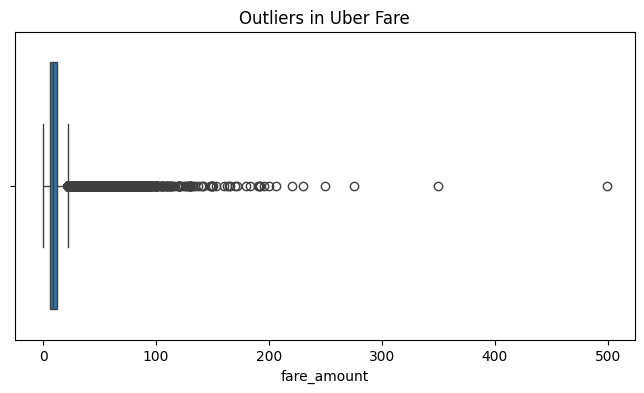

In [9]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Outliers in Uber Fare")
plt.show()

In [10]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = max(0, Q1 - 1.5 * IQR)
upper_limit = Q3 + 1.5 * IQR

df = df[
    df["fare_amount"].between(lower_limit, upper_limit)
].copy()

print("Fare limits:", lower_limit, "to", upper_limit)
print("Shape after outlier removal:", df.shape)

Fare limits: 0 to 22.25
Shape after outlier removal: (182136, 10)


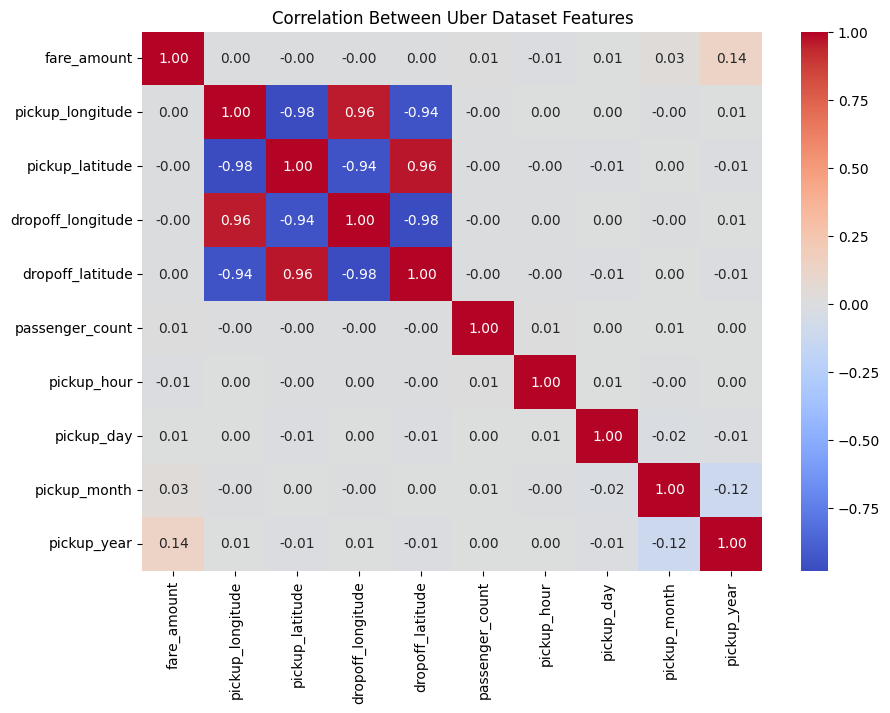

In [11]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Uber Dataset Features")
plt.show()

In [12]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 145708
Testing rows: 36428


In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [14]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

random_forest_predictions = random_forest_model.predict(X_test)

In [15]:
linear_r2 = r2_score(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))

rf_r2 = r2_score(y_test, random_forest_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, random_forest_predictions))

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regression"],
    "R2 Score": [linear_r2, rf_r2],
    "RMSE": [linear_rmse, rf_rmse]
})

print(results)

                      Model  R2 Score      RMSE
0         Linear Regression  0.019089  4.085366
1  Random Forest Regression  0.752057  2.053959


In [16]:
best_model = results.sort_values(
    by=["RMSE", "R2 Score"],
    ascending=[True, False]
).iloc[0]

print("Better performing model:", best_model["Model"])
print("R² score:", round(best_model["R2 Score"], 4))
print("RMSE:", round(best_model["RMSE"], 4))

Better performing model: Random Forest Regression
R² score: 0.7521
RMSE: 2.054


Here are **15 likely viva questions** for Practical 1, with short answers you can study.

1. **What is the aim of this practical?**  
   To predict Uber ride fares from trip details and compare regression models.

2. **What is the target variable?**  
   `fare_amount`, because that is the value the models predict.

3. **What are features?**  
   The input columns used to make predictions, such as pickup and drop-off coordinates, passenger count, and pickup time.

4. **Why did you remove `Unnamed: 0`?**  
   It is an extra row-number column and does not provide useful trip information.

5. **Why did you remove the `key` column?**  
   It acts as an identifier or timestamp string and was not used as a model feature.

6. **How did you handle missing values?**  
   I checked each column and removed rows containing missing values.

7. **What is an outlier?**  
   A value that is unusually far from most other values in the data.

8. **How did you identify fare outliers?**  
   I plotted the fare values with a box plot and used the IQR method.

9. **What is IQR?**  
   The interquartile range: \(Q3 - Q1\). It measures the spread of the middle half of the data.

10. **What does the correlation heatmap show?**  
    It shows how strongly numeric columns are related. Correlation ranges from −1 to +1.

11. **What is regression?**  
    A machine-learning method used to predict a numeric value, such as a fare.

12. **What is Linear Regression?**  
    A model that predicts an output by fitting a straight-line relationship between input features and the target.

13. **What is Random Forest Regression?**  
    A model that combines predictions from many decision trees to predict a numeric value.

14. **What do R² and RMSE measure?**  
    R² indicates how much variation the model explains; higher is generally better. RMSE measures the typical prediction error; lower is better.

15. **Which model performed better, and how do you know?**  
    Random Forest Regression. It had a higher R² (**0.7521**) and a lower RMSE (**2.0540**) than Linear Regression.

**A question you may be asked about your cleaning:** *Did removing fares above 22.25 remove every unusual fare correctly?*  
A good answer is: “I used the IQR rule to remove unusually high fares, but some high fares could be genuine trips. The cutoff is a cleaning choice, so I would mention it as a limitation.”